# VideoMamba-Tiny — CTPGesture_v1 Evaluation Only

This notebook evaluates an already fine-tuned **VideoMamba-Tiny** checkpoint on the official `CTPGesture_v1 / police_gesture_v1 / test` split.

There is **no training cell** and no dependency on training-generated `0.txt` / `1.txt` prediction files.

## Required Kaggle inputs

Attach these three inputs before running:

1. **CTPGesture_v1** data containing:
   ```text
   CTPGesture_v1/
   └── police_gesture_v1/
       ├── train/
       └── test/
   ```

2. The CPython 3.12 CUDA wheels:
   ```text
   causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
   mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl
   ```

3. The saved fine-tuned Kaggle Model containing:
   ```text
   checkpoint-best.pth
   ```

Preferred checkpoint path:
```text
/kaggle/input/models/hoanganh94/videomambactpgesturev1best/
pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
```

`checkpoint-latest.pth` is not required for evaluation.

## Evaluation protocol

- Model: VideoMamba-Tiny
- Classes: 9
- Frames/view: 16
- Sampling rate: 2
- Resolution: 224 × 224
- Precision: FP32
- Official test videos: `002,004,008,010,012,014,016,018,101,102,104`
- Single-view evaluation: deterministic center temporal window + center spatial crop
- 12-view evaluation: `4 temporal × 3 spatial`
- Metrics:
  - Accuracy
  - Top-5 Accuracy for 12-view
  - Balanced Accuracy
  - Macro Precision / Recall / F1
  - Weighted F1
  - Per-class classification report
  - Normalized confusion matrix
  - Parameter count
  - FVCore GFLOPs estimate

> The notebook is designed for the same CPython 3.12 / CUDA environment used by the training notebook.

## CELL 1 — Configuration and Input Discovery

In [1]:
import os
import sys
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# ============================================================
# Fixed experiment configuration
# ============================================================

NUM_CLASSES = 9

CLASS_NAMES = {
    0: "No Gesture",
    1: "Stop",
    2: "Forward",
    3: "Left Turn",
    4: "Left Turn Waiting",
    5: "Right Turn",
    6: "Lane Changing",
    7: "Slow Down",
    8: "Pull Over",
}

TEST_IDS = [
    "002", "004", "008", "010", "012", "014",
    "016", "018", "101", "102", "104",
]

MODEL_NAME = "videomamba_tiny"
NUM_FRAMES = 16
SAMPLING_RATE = 2
TUBELET_SIZE = 1
INPUT_SIZE = 224
SHORT_SIDE_SIZE = 224

DROP_PATH = 0.1
FC_DROP_RATE = 0.3

TEST_NUM_SEGMENT = 4
TEST_NUM_CROP = 3
EXPECTED_VIEWS = TEST_NUM_SEGMENT * TEST_NUM_CROP

# Evaluation switches
RUN_SINGLE_VIEW = True
RUN_12_VIEW = True

# Number of views forwarded at once during 12-view evaluation.
# Reduce to 4 or 2 only if CUDA OOM occurs.
VIEW_BATCH_SIZE = 6

INPUT_ROOT = Path("/kaggle/input")
OUTPUT_DIR = Path("/kaggle/working/videomamba_ctpgesture_evaluation")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Optional manual overrides.
DATA_ROOT_OVERRIDE = None

# Preferred Kaggle Model path created from the saved training output.
# If this exact path exists, it is used immediately.
PREFERRED_CHECKPOINT = Path(
    "/kaggle/input/models/hoanganh94/"
    "videomambactpgesturev1best/"
    "pytorch/tiny-16x2-224-fp32/1/"
    "checkpoint-best.pth"
)

# Set this only if you want to force another checkpoint path.
CHECKPOINT_OVERRIDE = None

# ============================================================
# Locate CTPGesture_v1
# ============================================================

if DATA_ROOT_OVERRIDE is not None:
    DATA_ROOT = Path(DATA_ROOT_OVERRIDE)
else:
    dataset_candidates = [
        p for p in INPUT_ROOT.glob("**/CTPGesture_v1/police_gesture_v1")
        if (p / "train").is_dir() and (p / "test").is_dir()
    ]

    if not dataset_candidates:
        dataset_candidates = [
            p for p in INPUT_ROOT.glob("**/police_gesture_v1")
            if (p / "train").is_dir() and (p / "test").is_dir()
        ]

    if not dataset_candidates:
        raise FileNotFoundError(
            "Cannot find CTPGesture_v1/police_gesture_v1 under /kaggle/input."
        )

    dataset_candidates = sorted(
        set(dataset_candidates),
        key=lambda p: (len(p.parts), str(p)),
    )

    print("Dataset candidates:")
    for p in dataset_candidates:
        print(" -", p)

    DATA_ROOT = dataset_candidates[0]

TEST_DIR = DATA_ROOT / "test"

# ============================================================
# Locate checkpoint-best.pth
# ============================================================

if CHECKPOINT_OVERRIDE is not None:
    BEST_CHECKPOINT = Path(CHECKPOINT_OVERRIDE)

elif PREFERRED_CHECKPOINT.is_file():
    BEST_CHECKPOINT = PREFERRED_CHECKPOINT
    print("\nUsing preferred checkpoint:")
    print(" -", BEST_CHECKPOINT)

else:
    checkpoint_candidates = sorted(
        INPUT_ROOT.rglob("checkpoint-best.pth"),
        key=lambda p: (
            "videomambactpgesturev1best" not in str(p).lower(),
            "tiny-16x2-224-fp32" not in str(p).lower(),
            "/models/" not in str(p).lower(),
            len(p.parts),
            str(p),
        ),
    )

    if not checkpoint_candidates:
        raise FileNotFoundError(
            "Cannot find checkpoint-best.pth under /kaggle/input. "
            "Attach the Kaggle Model that contains the saved best checkpoint."
        )

    print("\nCheckpoint candidates:")
    for p in checkpoint_candidates:
        print(" -", p)

    BEST_CHECKPOINT = checkpoint_candidates[0]

    print("\nSelected checkpoint:")
    print(" -", BEST_CHECKPOINT)

print("\n" + "=" * 72)
print("EVALUATION CONFIGURATION")
print("=" * 72)
print("Python                 :", sys.version.split()[0])
print("PyTorch                :", torch.__version__)
print("CUDA                   :", torch.version.cuda)
print("CUDA available         :", torch.cuda.is_available())
print("GPU count              :", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i:19d}: {torch.cuda.get_device_name(i)}")
print("Dataset root           :", DATA_ROOT)
print("Official test dir      :", TEST_DIR)
print("Best checkpoint        :", BEST_CHECKPOINT)
print("Model                  :", MODEL_NAME)
print("Frames                 :", NUM_FRAMES)
print("Sampling rate          :", SAMPLING_RATE)
print("Resolution             :", f"{INPUT_SIZE}x{INPUT_SIZE}")
print("12-view protocol       :", f"{TEST_NUM_SEGMENT} temporal x {TEST_NUM_CROP} spatial")
print("Output                 :", OUTPUT_DIR)
print("=" * 72)

assert TEST_DIR.is_dir()
assert BEST_CHECKPOINT.is_file()
assert torch.cuda.is_available(), "A CUDA GPU is required."

Dataset candidates:
 - /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1

Using preferred checkpoint:
 - /kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth

EVALUATION CONFIGURATION
Python                 : 3.12.13
PyTorch                : 2.10.0+cu128
CUDA                   : 12.8
CUDA available         : True
GPU count              : 2
GPU                   0: Tesla T4
GPU                   1: Tesla T4
Dataset root           : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1
Official test dir      : /kaggle/input/notebooks/hoanganh94/ctpgesturev1-videomambatiny/CTPGesture_v1/police_gesture_v1/test
Best checkpoint        : /kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
Model                  : videomamba_tiny
Frames                 : 16
Sampling rate          : 2
Resolution      

In [2]:
from pathlib import Path

print("=" * 72)
print("CHECKPOINT INPUT CHECK")
print("=" * 72)
print("Selected checkpoint:")
print(BEST_CHECKPOINT)

if not BEST_CHECKPOINT.is_file():
    raise FileNotFoundError(BEST_CHECKPOINT)

print(f"Size: {BEST_CHECKPOINT.stat().st_size / 1024**2:.2f} MiB")
print("[OK] checkpoint-best.pth is available.")
print("[INFO] checkpoint-latest.pth is not required.")


CHECKPOINT INPUT CHECK
Selected checkpoint:
/kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
Size: 80.14 MiB
[OK] checkpoint-best.pth is available.
[INFO] checkpoint-latest.pth is not required.


## CELL 2 — Set Up the Pinned VideoMamba Environment

In [3]:
import shutil
import subprocess
from pathlib import Path

import torch

VIDEOMAMBA_REPO = "https://github.com/OpenGVLab/VideoMamba.git"
VIDEOMAMBA_COMMIT = "37355c26d0ae99ca2459f6d4044a5f509031a79f"

REPO_DIR = Path("/kaggle/working/VideoMamba")
VIDEO_SM_DIR = REPO_DIR / "videomamba" / "video_sm"

def run(cmd, cwd=None):
    cmd = [str(x) for x in cmd]
    print("\n$", " ".join(cmd))
    subprocess.run(
        cmd,
        cwd=str(cwd) if cwd else None,
        check=True,
    )

# ============================================================
# Runtime check
# ============================================================

if sys.version_info[:2] != (3, 12):
    raise RuntimeError(
        "This evaluation notebook expects CPython 3.12 because the "
        "prebuilt CUDA wheels are cp312 binaries. "
        f"Current Python: {sys.version.split()[0]}"
    )

# ============================================================
# Locate prebuilt CUDA wheels
# ============================================================

causal_candidates = sorted(
    INPUT_ROOT.rglob(
        "causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl"
    )
)

mamba_candidates = sorted(
    INPUT_ROOT.rglob(
        "mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl"
    )
)

if not causal_candidates:
    raise FileNotFoundError(
        "Missing causal_conv1d-1.0.0 cp312 wheel under /kaggle/input."
    )

if not mamba_candidates:
    raise FileNotFoundError(
        "Missing mamba_ssm-1.0.1 cp312 wheel under /kaggle/input."
    )

CAUSAL_WHEEL = causal_candidates[0]
MAMBA_WHEEL = mamba_candidates[0]

print("causal_conv1d wheel:", CAUSAL_WHEEL)
print("mamba_ssm wheel    :", MAMBA_WHEEL)

# ============================================================
# Install only the dependencies needed for evaluation
# ============================================================

run([
    sys.executable, "-m", "pip", "install", "-q",
    "setuptools<82",
    "wheel",
    "packaging",
    "ninja",
    "einops==0.7.0",
    "decord==0.6.0",
    "timm==0.4.12",
    "transformers==4.36.1",
    "fvcore",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "tqdm",
])

run([
    sys.executable, "-m", "pip", "install",
    "--force-reinstall", "--no-deps",
    CAUSAL_WHEEL,
])

run([
    sys.executable, "-m", "pip", "install",
    "--force-reinstall", "--no-deps",
    MAMBA_WHEEL,
])

# ============================================================
# Prepare the exact VideoMamba source revision used in training
# ============================================================

if REPO_DIR.exists():
    shutil.rmtree(REPO_DIR)

run(["git", "clone", VIDEOMAMBA_REPO, REPO_DIR])
run(["git", "-C", REPO_DIR, "fetch", "origin", VIDEOMAMBA_COMMIT])
run(["git", "-C", REPO_DIR, "checkout", "--force", VIDEOMAMBA_COMMIT])

commit = subprocess.check_output(
    ["git", "-C", str(REPO_DIR), "rev-parse", "HEAD"],
    text=True,
).strip()

if commit != VIDEOMAMBA_COMMIT:
    raise RuntimeError(
        f"Unexpected VideoMamba commit: {commit}"
    )

if str(VIDEO_SM_DIR) not in sys.path:
    sys.path.insert(0, str(VIDEO_SM_DIR))

# ============================================================
# Validate CUDA extension import and BiMamba API
# ============================================================

import inspect
import causal_conv1d
import mamba_ssm
from mamba_ssm import Mamba

signature = inspect.signature(Mamba.__init__)

print("\nMamba signature:", signature)

if "bimamba" not in signature.parameters:
    raise RuntimeError(
        "Installed mamba_ssm does not expose the BiMamba API "
        "required by this VideoMamba revision."
    )

print("\n[OK] VideoMamba evaluation environment is ready.")
print("[OK] VideoMamba commit:", commit)

causal_conv1d wheel: /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
mamba_ssm wheel    : /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl

$ /usr/bin/python3 -m pip install -q setuptools<82 wheel packaging ninja einops==0.7.0 decord==0.6.0 timm==0.4.12 transformers==4.36.1 fvcore pandas scikit-learn matplotlib tqdm
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 126.8/126.8 kB 6.8 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 50.2/50.2 kB 2.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.6/44.6 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.6/13.6 MB 70.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 377.0/377.0 kB 17.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.3/8.3 MB 64.9 MB/s eta

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.4.1 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.1 which is incompatible.



$ /usr/bin/python3 -m pip install --force-reinstall --no-deps /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl
Processing /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/causal_conv1d-1.0.0-cp312-cp312-linux_x86_64.whl

$ /usr/bin/python3 -m pip install --force-reinstall --no-deps /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl
Processing /kaggle/input/datasets/hoanganh94/videomamba-t4-cuda-wheels-cp312-v2/mamba_ssm-1.0.1-cp312-cp312-linux_x86_64.whl

$ git clone https://github.com/OpenGVLab/VideoMamba.git /kaggle/working/VideoMamba


Cloning into '/kaggle/working/VideoMamba'...



$ git -C /kaggle/working/VideoMamba fetch origin 37355c26d0ae99ca2459f6d4044a5f509031a79f


From https://github.com/OpenGVLab/VideoMamba
 * branch            37355c26d0ae99ca2459f6d4044a5f509031a79f -> FETCH_HEAD
Note: switching to '37355c26d0ae99ca2459f6d4044a5f509031a79f'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

HEAD is now at 37355c2 Update MODEL_ZOO.md
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/selective_scan_interface.py:158: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/p


$ git -C /kaggle/working/VideoMamba checkout --force 37355c26d0ae99ca2459f6d4044a5f509031a79f


/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/triton/layernorm.py:508: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd
/usr/local/lib/python3.12/dist-packages/mamba_ssm/ops/triton/layernorm.py:567: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:441: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(
/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(



Mamba signature: (self, d_model, d_state=16, d_conv=4, expand=2, dt_rank='auto', dt_min=0.001, dt_max=0.1, dt_init='random', dt_scale=1.0, dt_init_floor=0.0001, conv_bias=True, bias=False, use_fast_path=True, layer_idx=None, device=None, dtype=None, bimamba=True)

[OK] VideoMamba evaluation environment is ready.
[OK] VideoMamba commit: 37355c26d0ae99ca2459f6d4044a5f509031a79f


/usr/local/lib/python3.12/dist-packages/transformers/utils/generic.py:309: FutureWarning: `torch.utils._pytree._register_pytree_node` is deprecated. Please use `torch.utils._pytree.register_pytree_node` instead.
  _torch_pytree._register_pytree_node(


## CELL 3 — Build the Official Test Temporal Segments

In [4]:
import re

import numpy as np
import pandas as pd
from decord import VideoReader, cpu

def read_ctp_labels(csv_path: Path) -> np.ndarray:
    text = csv_path.read_text(encoding="utf-8").strip()
    tokens = [
        x for x in re.split(r"[\s,]+", text)
        if x
    ]

    if not tokens:
        raise RuntimeError(f"Empty annotation file: {csv_path}")

    labels = np.asarray([int(x) for x in tokens], dtype=np.int64)

    if labels.min() < 0 or labels.max() >= NUM_CLASSES:
        raise ValueError(
            f"Labels outside [0, {NUM_CLASSES - 1}] in {csv_path}"
        )

    return labels

def contiguous_runs(labels: np.ndarray):
    if len(labels) == 0:
        return []

    starts = np.r_[
        0,
        np.flatnonzero(labels[1:] != labels[:-1]) + 1,
    ]
    ends = np.r_[
        starts[1:] - 1,
        len(labels) - 1,
    ]

    return [
        (int(s), int(e), int(labels[s]))
        for s, e in zip(starts, ends)
    ]

rows = []
global_uid = 0
audit_rows = []

for video_id in TEST_IDS:
    video_path = TEST_DIR / f"{video_id}.mp4"
    csv_path = TEST_DIR / f"{video_id}.csv"

    if not video_path.is_file():
        raise FileNotFoundError(video_path)

    if not csv_path.is_file():
        raise FileNotFoundError(csv_path)

    labels = read_ctp_labels(csv_path)

    reader = VideoReader(
        str(video_path),
        num_threads=1,
        ctx=cpu(0),
    )
    video_frames = len(reader)

    frame_diff = video_frames - len(labels)

    if abs(frame_diff) > 1:
        raise RuntimeError(
            f"{video_id}: MP4 frames={video_frames}, "
            f"CSV labels={len(labels)}, diff={frame_diff}"
        )

    audit_rows.append({
        "video_id": video_id,
        "video_frames": video_frames,
        "csv_labels": len(labels),
        "frame_diff": frame_diff,
    })

    for start0, end0, label in contiguous_runs(labels):
        # Convert 0-based inclusive indices to 1-based inclusive.
        rows.append({
            "sample_id": f"{video_id}_seg{global_uid:05d}",
            "video_id": video_id,
            "path": str(video_path),
            "label": label,
            "t_start": start0 + 1,
            "t_end": end0 + 1,
            "uid": global_uid,
            "segment_frames": end0 - start0 + 1,
        })
        global_uid += 1

test_frame = pd.DataFrame(rows)
audit_df = pd.DataFrame(audit_rows)

print("=" * 72)
print("OFFICIAL TEST SET")
print("=" * 72)
print("Videos            :", len(TEST_IDS))
print("Temporal segments :", len(test_frame))
print("12-view forwards  :", len(test_frame) * EXPECTED_VIEWS)
print()

display(audit_df)
display(
    test_frame.groupby(["label"])
    .size()
    .rename("segments")
    .to_frame()
    .assign(class_name=lambda x: [CLASS_NAMES[i] for i in x.index])
)

if len(test_frame) != 1728:
    print(
        "[WARNING] Expected 1728 temporal segments from the previously "
        f"verified dataset, but found {len(test_frame)}."
    )

TEST_SEGMENTS_CSV = OUTPUT_DIR / "official_test_segments.csv"
test_frame.to_csv(TEST_SEGMENTS_CSV, index=False)

print("\n[OK] Saved:", TEST_SEGMENTS_CSV)

OFFICIAL TEST SET
Videos            : 11
Temporal segments : 1728
12-view forwards  : 20736



,video_id,video_frames,csv_labels,frame_diff
0,002,10780,10780,0
1,004,4291,4291,0
2,008,5781,5781,0
3,010,5252,5252,0
4,012,6274,6274,0
5,014,6621,6621,0
6,016,6558,6558,0
7,018,5729,5729,0
8,101,5775,5775,0
9,102,5388,5388,0


,segments,class_name
label,,
0,869,No Gesture
1,106,Stop
2,106,Forward
3,106,Left Turn
4,112,Left Turn Waiting
5,106,Right Turn
6,108,Lane Changing
7,107,Slow Down
8,108,Pull Over



[OK] Saved: /kaggle/working/videomamba_ctpgesture_evaluation/official_test_segments.csv


## CELL 4 — Load `checkpoint-best.pth` and Report Model Complexity

In [5]:
import json

import torch
from fvcore.nn import FlopCountAnalysis

from models import videomamba_tiny
from models.videomamba import VisionMamba

device = torch.device("cuda:0")

# ============================================================
# Load the actual fine-tuned model
# ============================================================

model = videomamba_tiny(
    pretrained=False,
    img_size=INPUT_SIZE,
    num_frames=NUM_FRAMES,
    kernel_size=TUBELET_SIZE,
    num_classes=NUM_CLASSES,
    drop_path_rate=DROP_PATH,
    fc_drop_rate=FC_DROP_RATE,
)

try:
    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location="cpu",
        weights_only=False,
    )
except TypeError:
    checkpoint = torch.load(
        BEST_CHECKPOINT,
        map_location="cpu",
    )

if "model" not in checkpoint:
    raise KeyError(
        'checkpoint-best.pth does not contain the expected "model" key.'
    )

load_result = model.load_state_dict(
    checkpoint["model"],
    strict=True,
)

model = model.float().to(device).eval()

checkpoint_epoch_zero_based = checkpoint.get("epoch")
checkpoint_epoch_human = (
    int(checkpoint_epoch_zero_based) + 1
    if checkpoint_epoch_zero_based is not None
    else None
)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)
parameter_bytes = sum(
    p.numel() * p.element_size()
    for p in model.parameters()
)

print("=" * 72)
print("CHECKPOINT")
print("=" * 72)
print("Path                    :", BEST_CHECKPOINT)
print("Checkpoint epoch (0-based):", checkpoint_epoch_zero_based)
print("Checkpoint epoch          :", checkpoint_epoch_human)
print("State-dict load            : strict=True / OK")
print("Total params               :", f"{total_params:,}")
print("Trainable params           :", f"{trainable_params:,}")
print("FP32 parameter storage     :", f"{parameter_bytes / 2**20:.2f} MiB")

# ============================================================
# GFLOPs estimate
#
# VideoMamba source profiling uses an unfused normalization clone.
# Unsupported custom operators are reported explicitly.
# ============================================================

profile_model = VisionMamba(
    img_size=INPUT_SIZE,
    patch_size=16,
    depth=24,
    embed_dim=192,
    channels=3,
    num_classes=NUM_CLASSES,
    drop_rate=0.0,
    drop_path_rate=DROP_PATH,
    norm_epsilon=1e-5,
    fused_add_norm=False,
    rms_norm=False,
    residual_in_fp32=True,
    bimamba=True,
    kernel_size=TUBELET_SIZE,
    num_frames=NUM_FRAMES,
    fc_drop_rate=FC_DROP_RATE,
).float().to(device).eval()

dummy = torch.randn(
    1,
    3,
    NUM_FRAMES,
    INPUT_SIZE,
    INPUT_SIZE,
    device=device,
    dtype=torch.float32,
)

flop_analyzer = FlopCountAnalysis(profile_model, dummy)

try:
    flop_analyzer.unsupported_ops_warnings(False)
    flop_analyzer.uncalled_modules_warnings(False)
    flop_analyzer.tracer_warnings("none")
except Exception:
    pass

try:
    total_flops = float(flop_analyzer.total())
    unsupported_ops = {
        str(k): int(v)
        for k, v in flop_analyzer.unsupported_ops().items()
    }
    gflops_per_view = total_flops / 1e9
except Exception as exc:
    total_flops = None
    gflops_per_view = None
    unsupported_ops = {
        "profiling_error": repr(exc)
    }

gflops_12view = (
    gflops_per_view * EXPECTED_VIEWS
    if gflops_per_view is not None
    else None
)

model_profile = {
    "model": MODEL_NAME,
    "checkpoint": str(BEST_CHECKPOINT),
    "checkpoint_epoch_zero_based": checkpoint_epoch_zero_based,
    "checkpoint_epoch": checkpoint_epoch_human,
    "input_shape": [1, 3, NUM_FRAMES, INPUT_SIZE, INPUT_SIZE],
    "total_params": int(total_params),
    "trainable_params": int(trainable_params),
    "total_params_M": total_params / 1e6,
    "parameter_storage_MiB_fp32": parameter_bytes / 2**20,
    "gflops_per_view_fvcore": gflops_per_view,
    "test_views": EXPECTED_VIEWS,
    "nominal_gflops_per_12view_sample": gflops_12view,
    "fvcore_unsupported_ops": unsupported_ops,
}

print("\n" + "=" * 72)
print("MODEL COMPLEXITY")
print("=" * 72)
print(f"Params                  : {total_params / 1e6:.3f} M")

if gflops_per_view is not None:
    print(f"GFLOPs / view           : {gflops_per_view:.4f}")
    print(f"Nominal GFLOPs / 12-view: {gflops_12view:.4f}")
else:
    print("GFLOPs                  : profiling failed")

print("FVCore unsupported ops  :", unsupported_ops)

MODEL_PROFILE_PATH = OUTPUT_DIR / "model_complexity.json"
MODEL_PROFILE_PATH.write_text(
    json.dumps(model_profile, indent=2, default=str),
    encoding="utf-8",
)

print("\n[OK] Saved:", MODEL_PROFILE_PATH)

del profile_model
del dummy
torch.cuda.empty_cache()

Use checkpoint: False
Checkpoint number: 0
CHECKPOINT
Path                    : /kaggle/input/models/hoanganh94/videomambactpgesturev1best/pytorch/tiny-16x2-224-fp32/1/checkpoint-best.pth
Checkpoint epoch (0-based): 17
Checkpoint epoch          : 18
State-dict load            : strict=True / OK
Total params               : 6,959,817
Trainable params           : 6,959,817
FP32 parameter storage     : 26.55 MiB
Use checkpoint: False
Checkpoint number: 0

MODEL COMPLEXITY
Params                  : 6.960 M
GFLOPs / view           : 17.1902
Nominal GFLOPs / 12-view: 206.2826
FVCore unsupported ops  : {'aten::mul': 81, 'aten::add': 50, 'aten::mul_': 26, 'aten::exp': 48, 'aten::neg': 48, 'prim::PythonOp.MambaInnerFnNoOutProj': 48, 'aten::flip': 48}

[OK] Saved: /kaggle/working/videomamba_ctpgesture_evaluation/model_complexity.json


## CELL 5 — Deterministic Video Sampling and Spatial Preprocessing

In [6]:
import numpy as np
import torch
from decord import VideoReader, cpu
from torchvision.transforms import functional as TF
from torchvision.transforms import InterpolationMode

IMAGENET_MEAN = torch.tensor(
    [0.485, 0.456, 0.406],
    dtype=torch.float32,
).view(1, 3, 1, 1)

IMAGENET_STD = torch.tensor(
    [0.229, 0.224, 0.225],
    dtype=torch.float32,
).view(1, 3, 1, 1)

def segment_bounds(total_frames, t_start_1b, t_end_1b):
    seg_start = max(0, int(t_start_1b) - 1)
    seg_end = min(total_frames, int(t_end_1b))
    seg_len = seg_end - seg_start

    if seg_len <= 0:
        raise ValueError(
            f"Empty temporal segment: start={t_start_1b}, end={t_end_1b}"
        )

    return seg_start, seg_end, seg_len

def center_segment_indices(
    total_frames,
    t_start_1b,
    t_end_1b,
):
    """
    Single-view deterministic center sampling.
    Matches the validation-style temporal logic used in the training notebook.
    """
    seg_start, _, seg_len = segment_bounds(
        total_frames,
        t_start_1b,
        t_end_1b,
    )

    converted_len = NUM_FRAMES * SAMPLING_RATE

    if seg_len <= converted_len:
        n = max(1, seg_len // SAMPLING_RATE)

        index = np.linspace(
            0,
            seg_len,
            num=n,
        )

        if n < NUM_FRAMES:
            index = np.concatenate([
                index,
                np.ones(NUM_FRAMES - n) * seg_len,
            ])

        index = np.clip(
            index,
            0,
            seg_len - 1,
        ).astype(np.int64)

    else:
        local_start = (
            seg_len - converted_len
        ) // 2

        local_end = (
            local_start + converted_len
        )

        index = np.linspace(
            local_start,
            local_end,
            num=NUM_FRAMES,
        )

        index = np.clip(
            index,
            local_start,
            local_end - 1,
        ).astype(np.int64)

    return index + seg_start

def temporal_view_indices(
    total_frames,
    t_start_1b,
    t_end_1b,
    chunk_nb,
):
    """
    Exact 4-view temporal sampling logic used by the custom CTPGesture
    test loader from the training notebook.
    """
    seg_start, _, seg_len = segment_bounds(
        total_frames,
        t_start_1b,
        t_end_1b,
    )

    converted_len = NUM_FRAMES * SAMPLING_RATE

    if TEST_NUM_SEGMENT > 1:
        temporal_step = max(
            1.0 * (seg_len - converted_len)
            / (TEST_NUM_SEGMENT - 1),
            0,
        )
    else:
        temporal_step = 0

    local_start = int(
        chunk_nb * temporal_step
    )

    bound = min(
        local_start + converted_len,
        seg_len,
    )

    local_indices = list(
        range(
            local_start,
            bound,
            SAMPLING_RATE,
        )
    )

    if not local_indices:
        local_indices = [0]

    while len(local_indices) < NUM_FRAMES:
        local_indices.append(
            local_indices[-1]
        )

    local_indices = local_indices[:NUM_FRAMES]

    return np.asarray(
        [
            seg_start + x
            for x in local_indices
        ],
        dtype=np.int64,
    )

def frames_to_resized_tensor(frames):
    """
    THWC uint8 NumPy -> TCHW float tensor.
    Resize the short side to SHORT_SIDE_SIZE while preserving aspect ratio.
    """
    clip = (
        torch.from_numpy(frames)
        .permute(0, 3, 1, 2)
        .float()
        / 255.0
    )

    clip = TF.resize(
        clip,
        SHORT_SIDE_SIZE,
        interpolation=InterpolationMode.BILINEAR,
        antialias=True,
    )

    return clip

def normalize_clip(clip_tchw):
    return (
        clip_tchw - IMAGENET_MEAN
    ) / IMAGENET_STD

def center_spatial_crop(clip_tchw):
    _, _, h, w = clip_tchw.shape

    top = max((h - INPUT_SIZE) // 2, 0)
    left = max((w - INPUT_SIZE) // 2, 0)

    crop = clip_tchw[
        :,
        :,
        top:top + INPUT_SIZE,
        left:left + INPUT_SIZE,
    ]

    if crop.shape[-2:] != (INPUT_SIZE, INPUT_SIZE):
        raise RuntimeError(
            f"Unexpected center crop shape: {tuple(crop.shape)}"
        )

    return crop

def uniform_spatial_crop(clip_tchw, split_nb):
    """
    Exact 3-crop test logic:
    crop along the longer spatial dimension after short-side resize.
    """
    _, _, h, w = clip_tchw.shape

    if TEST_NUM_CROP > 1:
        spatial_step = (
            max(h, w) - SHORT_SIDE_SIZE
        ) / (TEST_NUM_CROP - 1)
    else:
        spatial_step = 0.0

    spatial_start = int(
        split_nb * spatial_step
    )

    if h >= w:
        crop = clip_tchw[
            :,
            :,
            spatial_start:spatial_start + SHORT_SIDE_SIZE,
            :,
        ]
    else:
        crop = clip_tchw[
            :,
            :,
            :,
            spatial_start:spatial_start + SHORT_SIDE_SIZE,
        ]

    if crop.shape[-2:] != (INPUT_SIZE, INPUT_SIZE):
        raise RuntimeError(
            f"Unexpected spatial crop shape: {tuple(crop.shape)}"
        )

    return crop

def to_model_input(clip_tchw):
    """
    T C H W -> C T H W
    """
    clip_tchw = normalize_clip(clip_tchw)

    return (
        clip_tchw
        .permute(1, 0, 2, 3)
        .contiguous()
    )

def infer_views(view_tensors, batch_size=VIEW_BATCH_SIZE):
    """
    Run one or more CTHW views and return softmax probabilities on CPU.
    """
    all_probs = []

    with torch.inference_mode():
        for start in range(
            0,
            len(view_tensors),
            batch_size,
        ):
            batch = torch.stack(
                view_tensors[
                    start:start + batch_size
                ]
            ).to(
                device,
                dtype=torch.float32,
                non_blocking=True,
            )

            logits = model(batch)

            if not torch.isfinite(logits).all():
                raise FloatingPointError(
                    "Non-finite logits detected."
                )

            probs = torch.softmax(
                logits,
                dim=1,
            ).cpu()

            all_probs.append(probs)

    return torch.cat(
        all_probs,
        dim=0,
    ).numpy()

print("[OK] Sampling and preprocessing helpers are ready.")

[OK] Sampling and preprocessing helpers are ready.


## CELL 6 — Official Test: Single-View Evaluation

Single-view FP32:   0%|          | 0/1728 [00:00<?, ?it/s]


TEST RESULTS — SINGLE VIEW
accuracy            : 0.9792
balanced_accuracy   : 0.9780
macro_precision     : 0.9722
macro_recall        : 0.9780
macro_f1            : 0.9745
weighted_f1         : 0.9793


,precision,recall,f1-score,support
0 - No Gesture,0.990698,0.980437,0.985541,869.000000
1 - Stop,1.000000,0.933962,0.965854,106.000000
2 - Forward,1.000000,0.962264,0.980769,106.000000
3 - Left Turn,1.000000,1.000000,1.000000,106.000000
4 - Left Turn Waiting,0.909836,0.991071,0.948718,112.000000
5 - Right Turn,0.990654,1.000000,0.995305,106.000000
6 - Lane Changing,0.946903,0.990741,0.968326,108.000000
7 - Slow Down,0.980583,0.943925,0.961905,107.000000
8 - Pull Over,0.931034,1.000000,0.964286,108.000000
accuracy,0.979167,0.979167,0.979167,0.979167


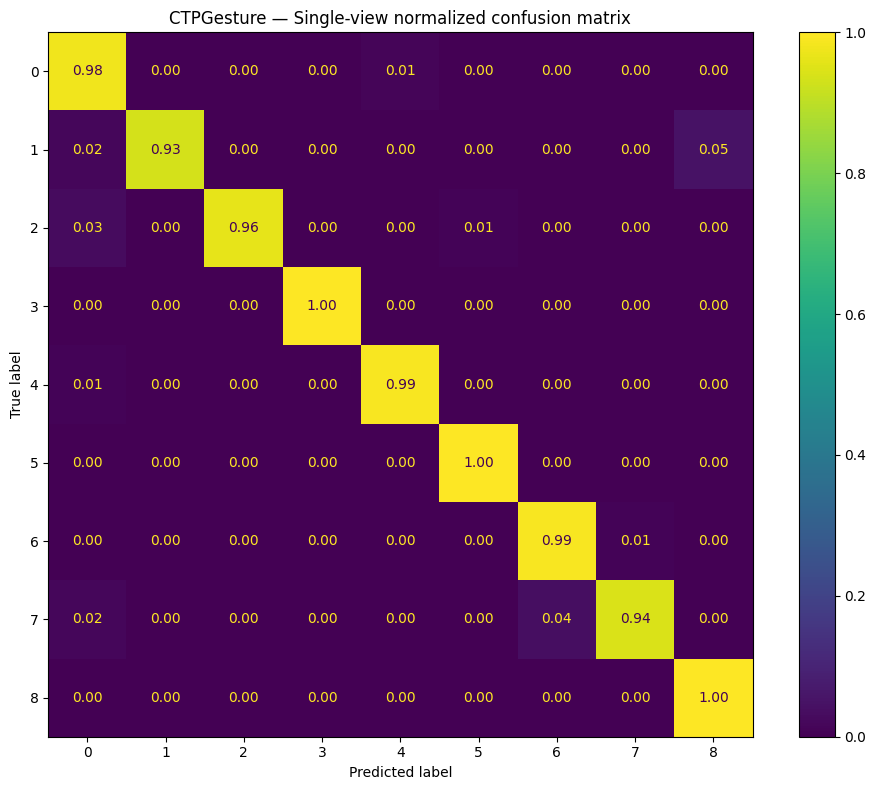

[OK] Saved single-view outputs to: /kaggle/working/videomamba_ctpgesture_evaluation


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)

CLASS_CODES = [str(i) for i in range(NUM_CLASSES)]
CLASS_LABELS = [
    f"{i} - {CLASS_NAMES[i]}"
    for i in range(NUM_CLASSES)
]

single_metrics = None
single_rows = []

if RUN_SINGLE_VIEW:
    y_true_single = []
    y_pred_single = []

    with torch.inference_mode():
        for row in tqdm(
            test_frame.itertuples(index=False),
            total=len(test_frame),
            desc="Single-view FP32",
        ):
            reader = VideoReader(
                row.path,
                num_threads=1,
                ctx=cpu(0),
            )

            idx = center_segment_indices(
                len(reader),
                row.t_start,
                row.t_end,
            )

            frames = reader.get_batch(
                idx.tolist()
            ).asnumpy()

            clip = frames_to_resized_tensor(
                frames
            )

            clip = center_spatial_crop(
                clip
            )

            view = to_model_input(
                clip
            )

            probs = infer_views(
                [view],
                batch_size=1,
            )[0]

            pred = int(
                np.argmax(probs)
            )
            true = int(
                row.label
            )

            y_true_single.append(
                true
            )
            y_pred_single.append(
                pred
            )

            single_rows.append({
                "sample_id": row.sample_id,
                "video_id": row.video_id,
                "uid": int(row.uid),
                "true": true,
                "pred": pred,
                "confidence": float(probs[pred]),
            })

    single_accuracy = accuracy_score(
        y_true_single,
        y_pred_single,
    )
    single_balanced = balanced_accuracy_score(
        y_true_single,
        y_pred_single,
    )
    single_macro_precision = precision_score(
        y_true_single,
        y_pred_single,
        average="macro",
        zero_division=0,
    )
    single_macro_recall = recall_score(
        y_true_single,
        y_pred_single,
        average="macro",
        zero_division=0,
    )
    single_macro_f1 = f1_score(
        y_true_single,
        y_pred_single,
        average="macro",
        zero_division=0,
    )
    single_weighted_f1 = f1_score(
        y_true_single,
        y_pred_single,
        average="weighted",
        zero_division=0,
    )

    single_metrics = {
        "accuracy": float(single_accuracy),
        "balanced_accuracy": float(single_balanced),
        "macro_precision": float(single_macro_precision),
        "macro_recall": float(single_macro_recall),
        "macro_f1": float(single_macro_f1),
        "weighted_f1": float(single_weighted_f1),
    }

    print()
    print("=" * 72)
    print("TEST RESULTS — SINGLE VIEW")
    print("=" * 72)
    for key, value in single_metrics.items():
        print(f"{key:20s}: {value:.4f}")

    single_report = classification_report(
        y_true_single,
        y_pred_single,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_LABELS,
        digits=4,
        zero_division=0,
        output_dict=True,
    )

    single_report_df = pd.DataFrame(
        single_report
    ).T

    display(
        single_report_df
    )

    single_report_df.to_csv(
        OUTPUT_DIR
        / "single_view_classification_report.csv"
    )

    pd.DataFrame(
        single_rows
    ).to_csv(
        OUTPUT_DIR
        / "single_view_predictions.csv",
        index=False,
    )

    cm_single = confusion_matrix(
        y_true_single,
        y_pred_single,
        labels=list(range(NUM_CLASSES)),
        normalize="true",
    )

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm_single,
        display_labels=CLASS_CODES,
    )

    disp.plot(
        ax=ax,
        values_format=".2f",
        colorbar=True,
    )

    ax.set_title(
        "CTPGesture — Single-view normalized confusion matrix"
    )
    ax.set_xlabel(
        "Predicted label"
    )
    ax.set_ylabel(
        "True label"
    )

    plt.tight_layout()

    single_cm_path = (
        OUTPUT_DIR
        / "single_view_confusion_matrix.png"
    )

    plt.savefig(
        single_cm_path,
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()

    print(
        "[OK] Saved single-view outputs to:",
        OUTPUT_DIR,
    )
else:
    print(
        "[SKIP] RUN_SINGLE_VIEW=False"
    )

## CELL 7 — Official Test: Direct 12-View Evaluation

This cell evaluates the checkpoint directly.

For every temporal segment:

1. sample 4 deterministic temporal views;
2. resize the short side to 224;
3. take 3 deterministic spatial crops along the longer dimension;
4. run all 12 views through the model;
5. apply softmax per view;
6. average the 12 probability vectors;
7. compute the final prediction.

This removes the old dependency on training-generated `0.txt` / `1.txt` files.

12-view FP32:   0%|          | 0/1728 [00:00<?, ?it/s]


TEST RESULTS — 12 VIEW
accuracy            : 0.9850
top5_accuracy       : 1.0000
balanced_accuracy   : 0.9838
macro_precision     : 0.9772
macro_recall        : 0.9838
macro_f1            : 0.9801
weighted_f1         : 0.9850
GFLOPs / view        : 17.1902
Nominal GFLOPs / sample: 206.2826


,precision,recall,f1-score,support
0 - No Gesture,0.996512,0.986191,0.991324,869.000000
1 - Stop,1.000000,0.943396,0.970874,106.000000
2 - Forward,1.000000,0.962264,0.980769,106.000000
3 - Left Turn,1.000000,1.000000,1.000000,106.000000
4 - Left Turn Waiting,0.941176,1.000000,0.969697,112.000000
5 - Right Turn,0.981481,1.000000,0.990654,106.000000
6 - Lane Changing,0.955357,0.990741,0.972727,108.000000
7 - Slow Down,0.981132,0.971963,0.976526,107.000000
8 - Pull Over,0.939130,1.000000,0.968610,108.000000
accuracy,0.984954,0.984954,0.984954,0.984954


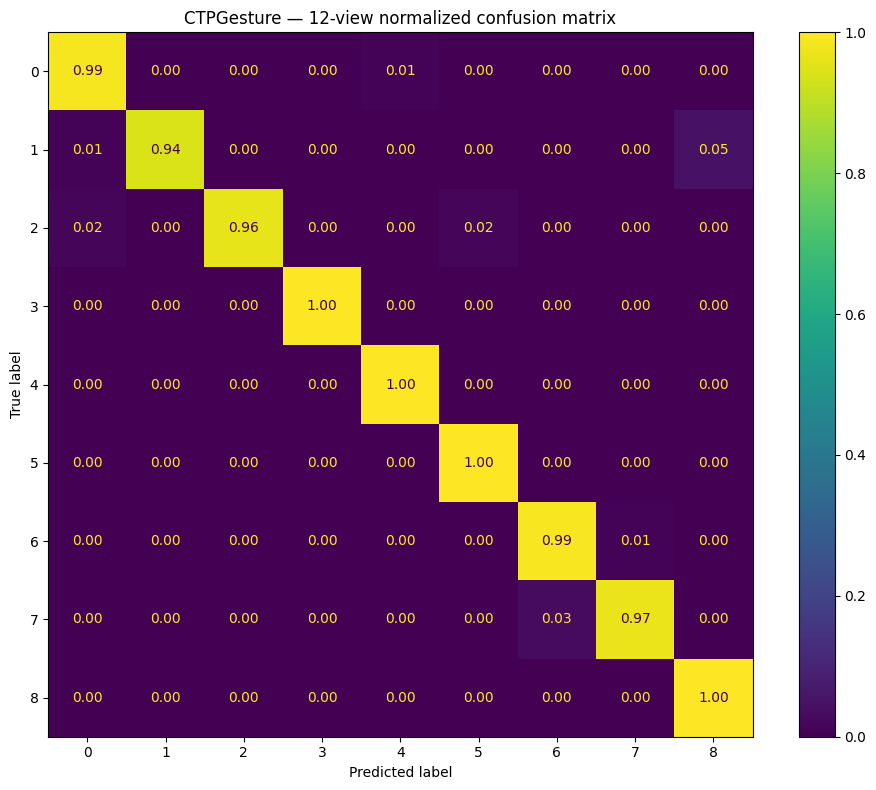

[OK] Saved 12-view outputs to: /kaggle/working/videomamba_ctpgesture_evaluation


In [8]:
import matplotlib.pyplot as plt
import pandas as pd
from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    ConfusionMatrixDisplay,
)

test12_metrics = None
rows_12 = []

if RUN_12_VIEW:
    y_true_12 = []
    y_pred_12 = []
    top5_hits = []

    for row in tqdm(
        test_frame.itertuples(index=False),
        total=len(test_frame),
        desc="12-view FP32",
    ):
        reader = VideoReader(
            row.path,
            num_threads=1,
            ctx=cpu(0),
        )

        views = []

        for chunk_nb in range(
            TEST_NUM_SEGMENT
        ):
            idx = temporal_view_indices(
                len(reader),
                row.t_start,
                row.t_end,
                chunk_nb,
            )

            frames = reader.get_batch(
                idx.tolist()
            ).asnumpy()

            resized = frames_to_resized_tensor(
                frames
            )

            for split_nb in range(
                TEST_NUM_CROP
            ):
                crop = uniform_spatial_crop(
                    resized,
                    split_nb,
                )

                views.append(
                    to_model_input(crop)
                )

        if len(views) != EXPECTED_VIEWS:
            raise RuntimeError(
                f"{row.sample_id}: expected "
                f"{EXPECTED_VIEWS} views, got {len(views)}."
            )

        view_probs = infer_views(
            views,
            batch_size=VIEW_BATCH_SIZE,
        )

        probs = view_probs.mean(
            axis=0
        )

        pred = int(
            np.argmax(probs)
        )
        true = int(
            row.label
        )

        top5 = np.argsort(
            -probs
        )[:5]

        y_true_12.append(
            true
        )
        y_pred_12.append(
            pred
        )
        top5_hits.append(
            int(true in top5)
        )

        rows_12.append({
            "sample_id": row.sample_id,
            "video_id": row.video_id,
            "uid": int(row.uid),
            "true": true,
            "pred": pred,
            "confidence": float(probs[pred]),
            "views": EXPECTED_VIEWS,
        })

    test12_accuracy = accuracy_score(
        y_true_12,
        y_pred_12,
    )
    test12_top5 = float(
        np.mean(top5_hits)
    )
    test12_balanced = balanced_accuracy_score(
        y_true_12,
        y_pred_12,
    )
    test12_macro_precision = precision_score(
        y_true_12,
        y_pred_12,
        average="macro",
        zero_division=0,
    )
    test12_macro_recall = recall_score(
        y_true_12,
        y_pred_12,
        average="macro",
        zero_division=0,
    )
    test12_macro_f1 = f1_score(
        y_true_12,
        y_pred_12,
        average="macro",
        zero_division=0,
    )
    test12_weighted_f1 = f1_score(
        y_true_12,
        y_pred_12,
        average="weighted",
        zero_division=0,
    )

    test12_metrics = {
        "accuracy": float(test12_accuracy),
        "top5_accuracy": float(test12_top5),
        "balanced_accuracy": float(test12_balanced),
        "macro_precision": float(test12_macro_precision),
        "macro_recall": float(test12_macro_recall),
        "macro_f1": float(test12_macro_f1),
        "weighted_f1": float(test12_weighted_f1),
    }

    print()
    print("=" * 72)
    print("TEST RESULTS — 12 VIEW")
    print("=" * 72)
    for key, value in test12_metrics.items():
        print(f"{key:20s}: {value:.4f}")

    if model_profile[
        "gflops_per_view_fvcore"
    ] is not None:
        print(
            f"GFLOPs / view        : "
            f"{model_profile['gflops_per_view_fvcore']:.4f}"
        )
        print(
            f"Nominal GFLOPs / sample: "
            f"{model_profile['nominal_gflops_per_12view_sample']:.4f}"
        )

    report12 = classification_report(
        y_true_12,
        y_pred_12,
        labels=list(range(NUM_CLASSES)),
        target_names=CLASS_LABELS,
        digits=4,
        zero_division=0,
        output_dict=True,
    )

    report12_df = pd.DataFrame(
        report12
    ).T

    display(
        report12_df
    )

    report12_df.to_csv(
        OUTPUT_DIR
        / "12view_classification_report.csv"
    )

    pd.DataFrame(
        rows_12
    ).to_csv(
        OUTPUT_DIR
        / "12view_predictions.csv",
        index=False,
    )

    cm12 = confusion_matrix(
        y_true_12,
        y_pred_12,
        labels=list(range(NUM_CLASSES)),
        normalize="true",
    )

    fig, ax = plt.subplots(
        figsize=(10, 8)
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm12,
        display_labels=CLASS_CODES,
    )

    disp.plot(
        ax=ax,
        values_format=".2f",
        colorbar=True,
    )

    ax.set_title(
        "CTPGesture — 12-view normalized confusion matrix"
    )
    ax.set_xlabel(
        "Predicted label"
    )
    ax.set_ylabel(
        "True label"
    )

    plt.tight_layout()

    cm12_path = (
        OUTPUT_DIR
        / "12view_confusion_matrix.png"
    )

    plt.savefig(
        cm12_path,
        dpi=250,
        bbox_inches="tight",
    )
    plt.show()

    print(
        "[OK] Saved 12-view outputs to:",
        OUTPUT_DIR,
    )
else:
    print(
        "[SKIP] RUN_12_VIEW=False"
    )

## CELL 8 — Comparison Table and Export Final Summary

In [9]:
import json
import pandas as pd

comparison_rows = []

if single_metrics is not None:
    comparison_rows.append({
        "evaluation": "Single-view",
        **single_metrics,
        "gflops_per_sample": model_profile[
            "gflops_per_view_fvcore"
        ],
    })

if test12_metrics is not None:
    comparison_rows.append({
        "evaluation": "12-view",
        **test12_metrics,
        "gflops_per_sample": model_profile[
            "nominal_gflops_per_12view_sample"
        ],
    })

comparison_df = pd.DataFrame(
    comparison_rows
)

print("=" * 72)
print("FINAL COMPARISON")
print("=" * 72)

if not comparison_df.empty:
    display(
        comparison_df.round(4)
    )

    comparison_df.to_csv(
        OUTPUT_DIR
        / "test_comparison.csv",
        index=False,
    )

final_summary = {
    "dataset": "CTPGesture_v1 / police_gesture_v1",
    "official_test_video_ids": TEST_IDS,
    "official_test_segments": int(len(test_frame)),
    "classes": CLASS_NAMES,
    "model": model_profile,
    "evaluation": {
        "single_view": single_metrics,
        "12_view": test12_metrics,
    },
    "protocol": {
        "num_frames": NUM_FRAMES,
        "sampling_rate": SAMPLING_RATE,
        "input_size": INPUT_SIZE,
        "precision": "FP32",
        "test_num_segment": TEST_NUM_SEGMENT,
        "test_num_crop": TEST_NUM_CROP,
        "views_per_segment": EXPECTED_VIEWS,
    },
}

SUMMARY_PATH = (
    OUTPUT_DIR
    / "evaluation_summary.json"
)

SUMMARY_PATH.write_text(
    json.dumps(
        final_summary,
        indent=2,
        default=str,
    ),
    encoding="utf-8",
)

print("\nSaved evaluation artifacts:")
for path in sorted(
    OUTPUT_DIR.iterdir()
):
    if path.is_file():
        print(
            f" - {path.name:45s} "
            f"{path.stat().st_size / 1024:.1f} KiB"
        )

print("\n[OK] Final summary:", SUMMARY_PATH)

FINAL COMPARISON


,evaluation,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,gflops_per_sample,top5_accuracy
0,Single-view,0.9792,0.9780,0.9722,0.9780,0.9745,0.9793,17.1902,NaN
1,12-view,0.9850,0.9838,0.9772,0.9838,0.9801,0.9850,206.2826,1.0



Saved evaluation artifacts:
 - 12view_classification_report.csv              0.8 KiB
 - 12view_confusion_matrix.png                   125.8 KiB
 - 12view_predictions.csv                        79.8 KiB
 - evaluation_summary.json                       2.0 KiB
 - model_complexity.json                         0.7 KiB
 - official_test_segments.csv                    243.1 KiB
 - single_view_classification_report.csv         0.8 KiB
 - single_view_confusion_matrix.png              134.9 KiB
 - single_view_predictions.csv                   74.7 KiB
 - test_comparison.csv                           0.4 KiB

[OK] Final summary: /kaggle/working/videomamba_ctpgesture_evaluation/evaluation_summary.json


## Notes

- This notebook never calls `run_class_finetuning.py`.
- The pretrained ImageNet VideoMamba checkpoint is **not required** because the fine-tuned `checkpoint-best.pth` already contains the complete model state.
- `checkpoint-latest.pth` is not required.
- The 12-view test is performed directly from the saved best checkpoint.
- If `VIEW_BATCH_SIZE = 6` causes CUDA OOM, reduce it to `4` or `2`; this changes memory usage only, not the evaluation protocol.
- FVCore may report unsupported custom Mamba operators. When that happens, the notebook records the unsupported operators instead of treating the FLOPs estimate as exact.